In [3]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
%matplotlib inline

In [4]:
df = pd.read_csv("8-fraud_detection.csv")

In [5]:
df.head()

,transaction_amount,transaction_risk_score,is_fraud
0,1.879910,-1.485035,0
1,0.377083,-2.238585,0
2,1.354312,-2.664638,0
3,-0.509843,-1.502950,0
4,0.863561,-1.906364,0


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 3 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   transaction_amount      10000 non-null  float64
 1   transaction_risk_score  10000 non-null  float64
 2   is_fraud                10000 non-null  int64  
dtypes: float64(2), int64(1)
memory usage: 234.5 KB


In [7]:
df["is_fraud"].unique()

array([0, 1])

In [8]:
df["is_fraud"].value_counts()

is_fraud
0    9846
1     154
Name: count, dtype: int64

In [9]:
# imbalance dataset

In [10]:
df.isnull().sum()

transaction_amount        0
transaction_risk_score    0
is_fraud                  0
dtype: int64

In [11]:
X=df.drop("is_fraud", axis=1)
y=df["is_fraud"]

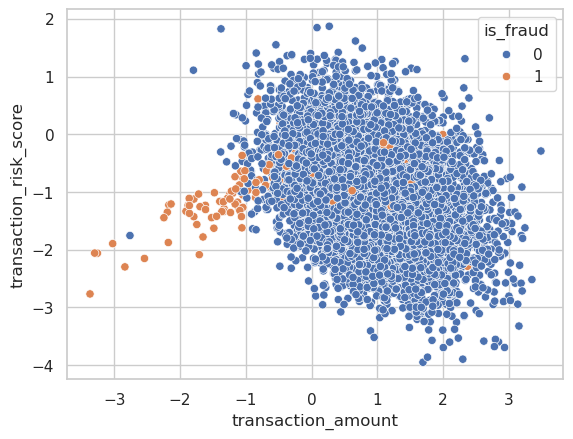

In [12]:
sns.set_theme(style=("whitegrid"))
sns.scatterplot(x=X["transaction_amount"], y=X["transaction_risk_score"], hue=y)
plt.show()

In [13]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X,y, test_size=0.3, random_state=42)

In [14]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression()

In [15]:
penalty = ["l1","l2","elasticnet"]
c_values = [100, 10, 1.0, 0.1, 0.01]
solver = ["newton-cg", "lbfgs", "liblinear", "saga", "sag", "newton_cholesky"]
class_weight = [{0:w, 1:y} for w in [1,10,50,100] for y in [1,10,50,100]]

In [16]:
class_weight

[{0: 1, 1: 1},
 {0: 1, 1: 10},
 {0: 1, 1: 50},
 {0: 1, 1: 100},
 {0: 10, 1: 1},
 {0: 10, 1: 10},
 {0: 10, 1: 50},
 {0: 10, 1: 100},
 {0: 50, 1: 1},
 {0: 50, 1: 10},
 {0: 50, 1: 50},
 {0: 50, 1: 100},
 {0: 100, 1: 1},
 {0: 100, 1: 10},
 {0: 100, 1: 50},
 {0: 100, 1: 100}]

In [17]:
params = dict(penalty=penalty, C=c_values, solver=solver, class_weight=class_weight)

In [18]:
from sklearn.model_selection import GridSearchCV, StratifiedKFold

In [19]:
cv = StratifiedKFold()

In [20]:
grid = GridSearchCV(estimator=model, param_grid=params, scoring="accuracy", cv=cv)

In [21]:
import warnings  # uyari mesajlarini engeller.
warnings.filterwarnings("ignore") 

In [22]:
grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=None, shuffle=False),
             estimator=LogisticRegression(),
             param_grid={'C': [100, 10, 1.0, 0.1, 0.01],
                         'class_weight': [{0: 1, 1: 1}, {0: 1, 1: 10},
                                          {0: 1, 1: 50}, {0: 1, 1: 100},
                                          {0: 10, 1: 1}, {0: 10, 1: 10},
                                          {0: 10, 1: 50}, {0: 10, 1: 100},
                                          {0: 50, 1: 1}, {0: 50, 1: 10},
                                          {0: 50, 1: 50}, {0: 50, 1: 100},
                                          {0: 100, 1: 1}, {0: 100, 1: 10},
                                          {0: 100, 1: 50}, {0: 100, 1: 100}],
                         'penalty': ['l1', 'l2', 'elasticnet'],
                         'solver': ['newton-cg', 'lbfgs', 'liblinear', 'saga',
                                    'sag', 'newton_cholesky']},
             scoring='accuracy')

In [23]:
y_pred = grid.predict(X_test)

In [24]:
y_pred

array([0, 0, 0, ..., 0, 0, 0])

In [25]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [26]:
print("score : ", accuracy_score(y_pred, y_test), "\n")
print(classification_report(y_pred, y_test))
print("Confusion Matrix : \n", confusion_matrix(y_pred, y_test))

score :  0.9886666666666667 

              precision    recall  f1-score   support

           0       1.00      0.99      0.99      2979
           1       0.36      0.81      0.50        21

    accuracy                           0.99      3000
   macro avg       0.68      0.90      0.75      3000
weighted avg       0.99      0.99      0.99      3000

Confusion Matrix : 
 [[2949   30]
 [   4   17]]


In [27]:
grid.best_params_

{'C': 0.01,
 'class_weight': {0: 10, 1: 50},
 'penalty': 'l2',
 'solver': 'newton-cg'}

In [28]:
grid.best_score_

np.float64(0.9887142857142857)

In [29]:
# roc, auc

The ROC Curve is a graphical representation of a classification model’s performance across different threshold values. It plots the True Positive Rate (Recall) on the Y-axis against the False Positive Rate (1 - Specificity) on the X-axis. • A model that perfectly distinguishes between classes has a curve that reaches the top-left corner. • The closer the curve is to the top-left, the better the model. • The area under the ROC curve (AUC) quantifies this performance: • AUC = 1 → perfect classifier • AUC = 0.5 → random guessing

ROC is especially useful for imbalanced datasets, as it evaluates the model independent of class distribution or threshold.

In [30]:
model_prob = grid.predict_proba(X_test)

In [31]:
model_prob

array([[0.84681192, 0.15318808],
       [0.9872012 , 0.0127988 ],
       [0.87278711, 0.12721289],
       ...,
       [0.96579328, 0.03420672],
       [0.98473714, 0.01526286],
       [0.96007251, 0.03992749]])

In [33]:
model_prob = model_prob[:,1] # probabilities for the positive (fraud) class

In [34]:
model_prob

array([0.15318808, 0.0127988 , 0.12721289, ..., 0.03420672, 0.01526286,
       0.03992749])

In [35]:
from sklearn.metrics import roc_curve, roc_auc_score

In [36]:
model_auc = roc_auc_score(y_test, model_prob)

In [37]:
model_auc

np.float64(0.7888623902126218)

In [45]:
# model false positive rate
# model true positive rate
model_fpr, model_tpr, thresholds = roc_curve(y_test, model_prob)

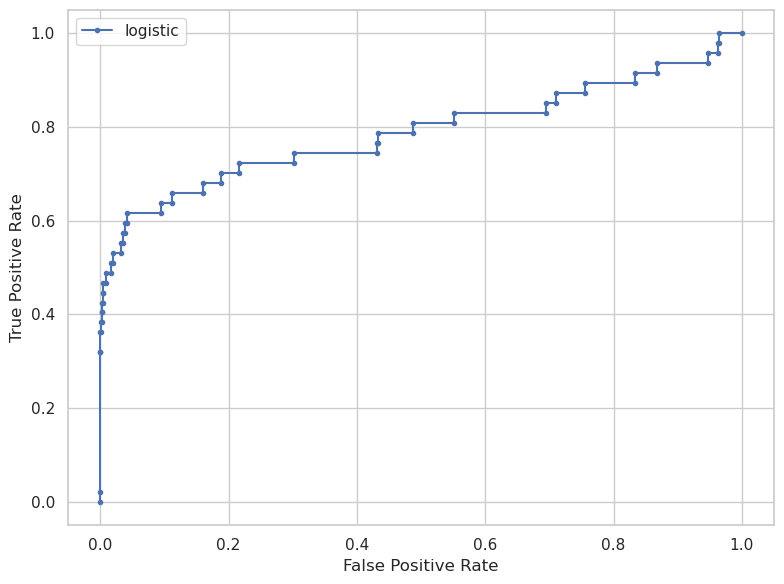

In [48]:
plt.figure(figsize=(8,6))
plt.plot(model_fpr, model_tpr, marker=".", label="logistic")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.legend()
plt.tight_layout()
plt.show()

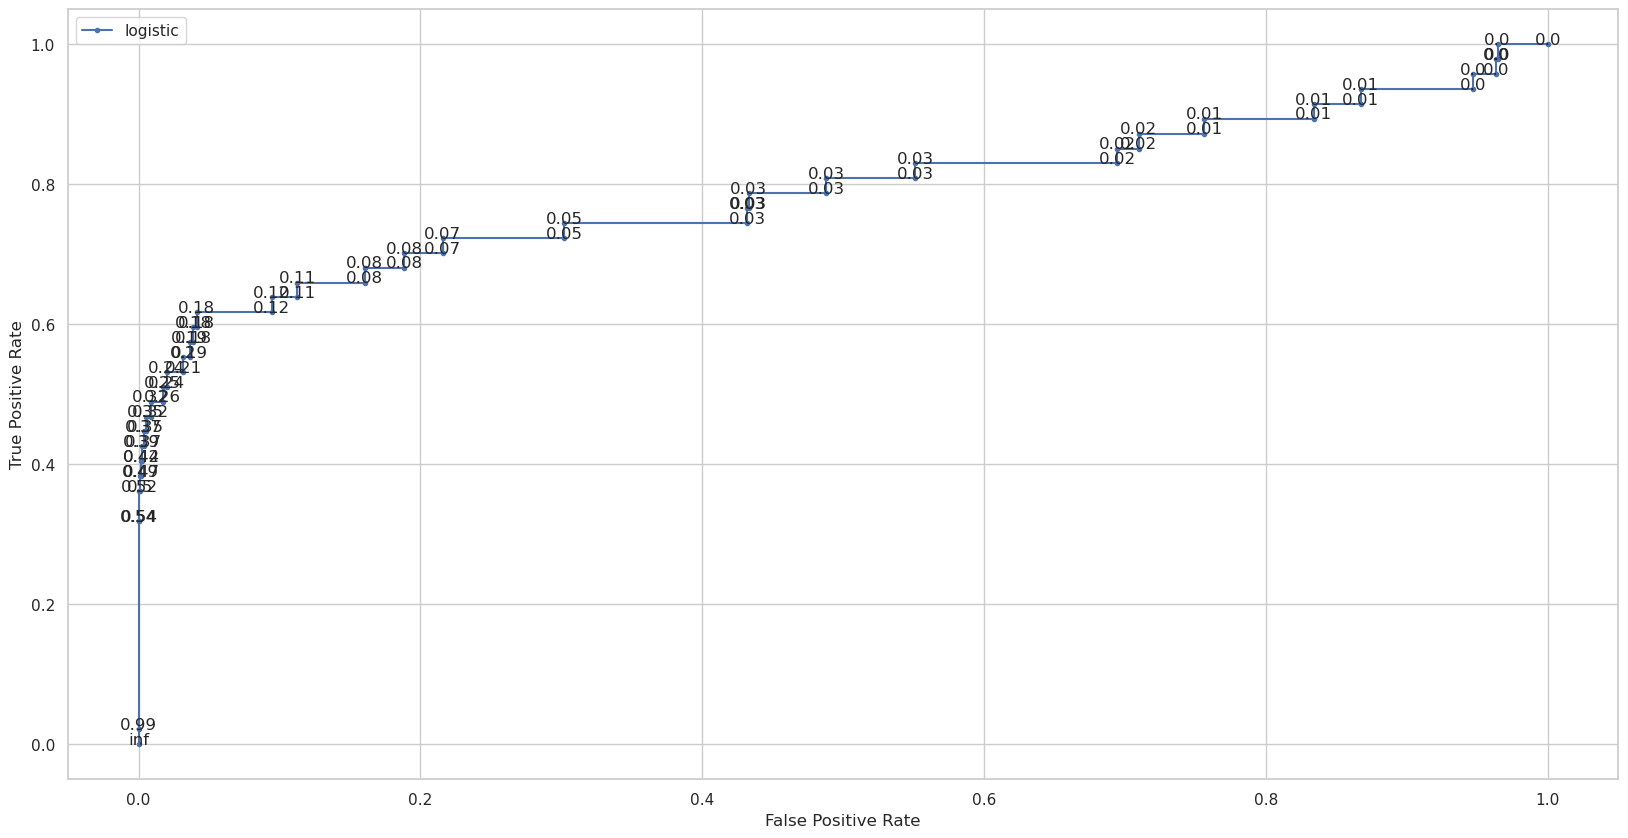

In [54]:
fig, ax = plt.subplots(figsize=(20,10))

ax.plot(model_fpr, model_tpr, marker=".", label="logistic")

for fpr, tpr, thresh in zip(model_fpr, model_tpr, thresholds):
    ax.annotate(f"{np.round(thresh, 2)}", (fpr, tpr), ha="center")

ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.legend()
plt.show()